# 03 – Presentation Charts

Ten presentation-ready charts of the most interesting findings from `02_eda.ipynb`.

**How the charts are designed:**
- **The title states the finding** (for example "Readmission rises with prior hospital stays"), and a grey subtitle says what is measured. Someone flicking through slides gets the point from the title alone.
- **One style and palette for every chart:** one blue for the data, grey for reference lines, light gridlines.
- **Only the most important bars carry a value label**, so the chart stays uncluttered. The full numbers are in `02_eda.ipynb`.

Every chart is saved to `reports/figures/` as a PNG at 150 dpi.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

PROJECT_DIR = Path.cwd().parent          # this notebook lives in notebooks/
sys.path.append(str(PROJECT_DIR))
from src.features import (AGE_ORDER, INSULIN_NAMES, MEDICATION_ORDER,
                          PRIOR_INPATIENT_ORDER, add_analysis_columns, rate_table)

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Style and helpers

`sns.set_theme()` sets one style for every chart. The helper functions keep titles, reference lines, labels and saving identical across charts.

In [2]:
# Colours
BLUE = "#2a78d6"          # the data
LIGHT_BLUE = "#cde2fb"    # box fill
TEXT = "#0b0b0b"          # titles
TEXT_SOFT = "#52514e"     # subtitles, axis labels
MUTED = "#898781"         # reference lines
GRID = "#e1e0d9"
BACKGROUND = "#fcfcfb"

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.15,       # larger text, readable on a slide
    rc={
        "figure.facecolor": BACKGROUND,
        "axes.facecolor": BACKGROUND,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": TEXT_SOFT,
        "xtick.color": TEXT_SOFT,
        "ytick.color": TEXT_SOFT,
        "grid.color": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    },
)

saved_files = []   # filled in by save_chart()


def add_titles(ax, title, subtitle):
    """Bold title (the finding) with a grey subtitle (what is measured) above the chart."""
    ax.text(0, 1.13, title, transform=ax.transAxes, fontsize=16, fontweight="bold", color=TEXT)
    ax.text(0, 1.05, subtitle, transform=ax.transAxes, fontsize=12, color=TEXT_SOFT)


def add_average_line(ax, value, label):
    """Grey horizontal reference line, labelled just outside the right edge of the chart."""
    ax.axhline(value, color=MUTED, linewidth=1.5)
    ax.text(1.01, value, label, transform=ax.get_yaxis_transform(),
            color=MUTED, va="center", ha="left", fontsize=11)


def label_bars(ax, positions, fmt="{:.0%}", horizontal=False):
    """Write the value on the chosen bars only (positions = bar numbers, starting at 0)."""
    for i in positions:
        bar = ax.patches[i]
        if horizontal:
            value = bar.get_width()
            ax.text(value, bar.get_y() + bar.get_height() / 2, "  " + fmt.format(value),
                    va="center", ha="left", color=TEXT, fontsize=11, fontweight="bold")
        else:
            value = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, value, fmt.format(value),
                    va="bottom", ha="center", color=TEXT, fontsize=11, fontweight="bold")


def save_chart(fig, filename):
    """Save the chart as a 150 dpi PNG in reports/figures/ and show it."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=150, bbox_inches="tight")
    saved_files.append(path)
    plt.show()

In [3]:
df = pd.read_csv(PROJECT_DIR / "data" / "processed" / "cleaned_data.csv", low_memory=False)
df = add_analysis_columns(df)

overall_rate = df["readmit_flag"].mean()
average_label = f"average\n{overall_rate:.1%}"
print(f"{len(df):,} patients, overall 30-day readmission rate {overall_rate:.1%}")

69,970 patients, overall 30-day readmission rate 9.0%


## 1. Prior hospital stays: the strongest pattern

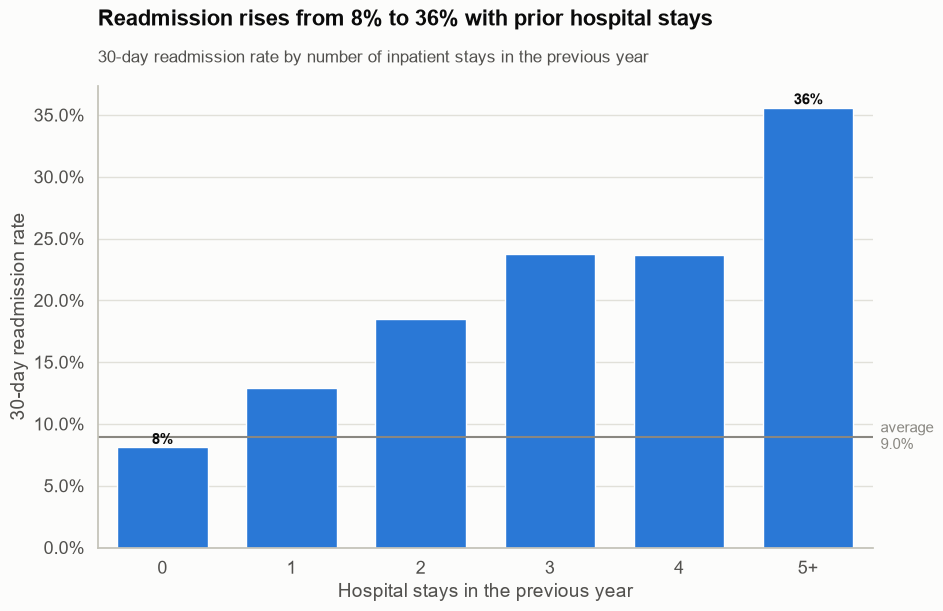

In [4]:
table = rate_table(df, "prior_inpatient", PRIOR_INPATIENT_ORDER)
first, last = table["readmission_rate"].iloc[0], table["readmission_rate"].iloc[-1]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=table, x="prior_inpatient", y="readmission_rate", color=BLUE, saturation=1, width=0.7, ax=ax)
add_average_line(ax, overall_rate, average_label)
label_bars(ax, [0, len(table) - 1])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Hospital stays in the previous year")
ax.set_ylabel("30-day readmission rate")
add_titles(ax, f"Readmission rises from {first:.0%} to {last:.0%} with prior hospital stays",
           "30-day readmission rate by number of inpatient stays in the previous year")
save_chart(fig, "readmission_by_prior_inpatient_visits.png")

## 2. Readmission by age group

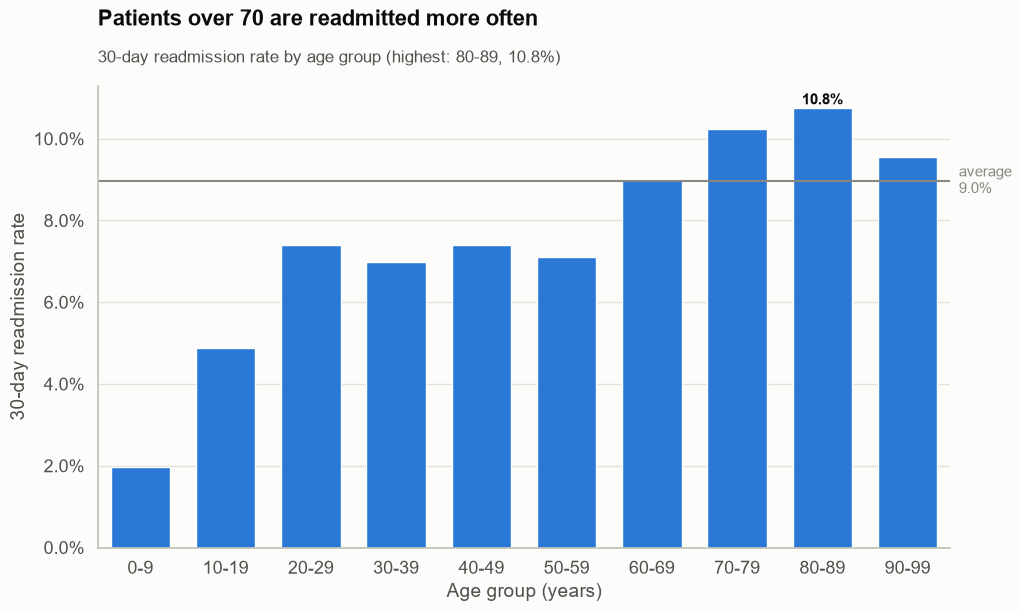

In [5]:
table = rate_table(df, "age_group", AGE_ORDER)
peak = table.loc[table["readmission_rate"].idxmax()]

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=table, x="age_group", y="readmission_rate", color=BLUE, saturation=1, width=0.7, ax=ax)
add_average_line(ax, overall_rate, average_label)
label_bars(ax, [table["readmission_rate"].idxmax()], fmt="{:.1%}")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Age group (years)")
ax.set_ylabel("30-day readmission rate")
add_titles(ax, "Patients over 70 are readmitted more often",
           f"30-day readmission rate by age group (highest: {peak['age_group']}, {peak['readmission_rate']:.1%})")
save_chart(fig, "readmission_by_age.png")

## 3. Readmission by number of medications

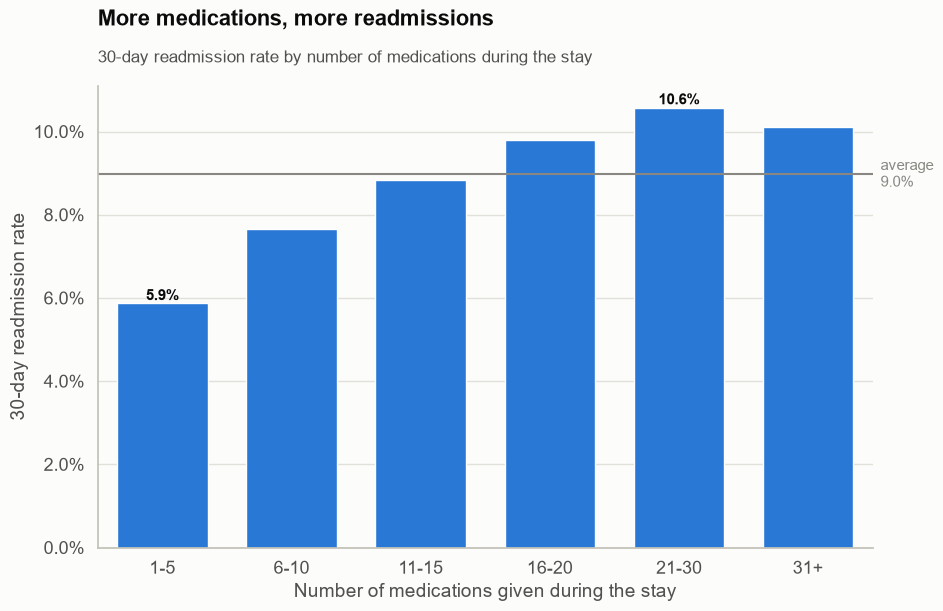

In [6]:
table = rate_table(df, "medication_range", MEDICATION_ORDER)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=table, x="medication_range", y="readmission_rate", color=BLUE, saturation=1, width=0.7, ax=ax)
add_average_line(ax, overall_rate, average_label)
label_bars(ax, [0, table["readmission_rate"].idxmax()], fmt="{:.1%}")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Number of medications given during the stay")
ax.set_ylabel("30-day readmission rate")
add_titles(ax, "More medications, more readmissions",
           "30-day readmission rate by number of medications during the stay")
save_chart(fig, "readmission_by_medication_count.png")

## 4. Most common reasons for admission

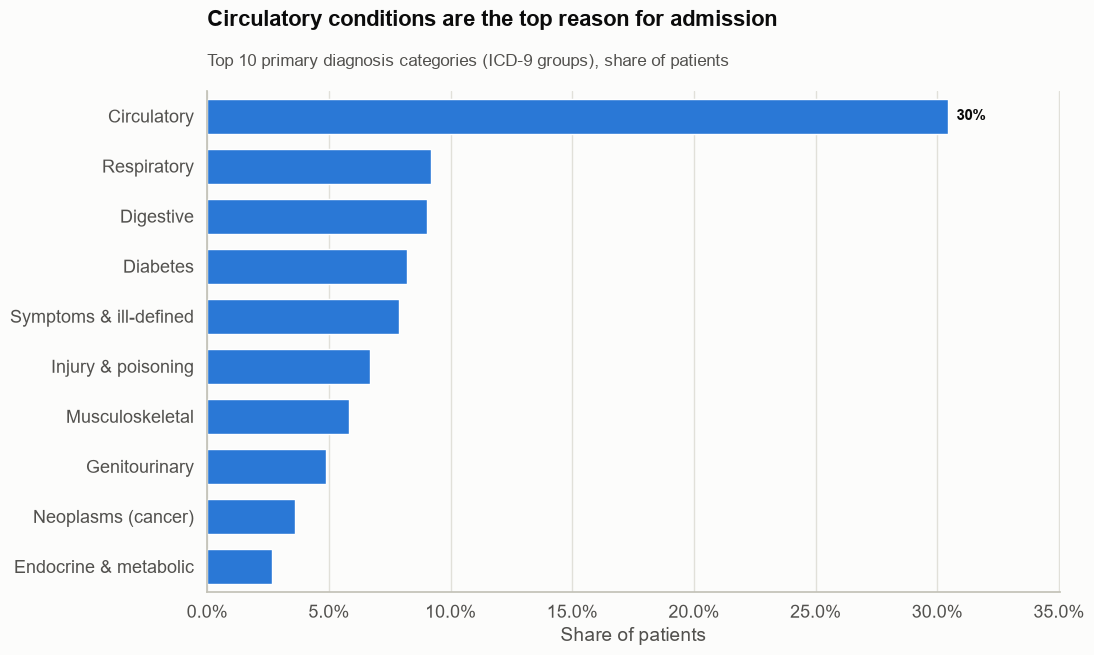

In [7]:
counts = df["diagnosis_category"].value_counts().head(10).reset_index()
counts.columns = ["diagnosis_category", "patients"]
counts["share"] = counts["patients"] / len(df)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(data=counts, y="diagnosis_category", x="share", color=BLUE, saturation=1, width=0.7, ax=ax)
label_bars(ax, [0], horizontal=True)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, counts["share"].max() * 1.15)
ax.set_xlabel("Share of patients")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
add_titles(ax, "Circulatory conditions are the top reason for admission",
           "Top 10 primary diagnosis categories (ICD-9 groups), share of patients")
save_chart(fig, "top_diagnosis_categories.png")

## 5. Readmission by diagnosis category

Same top 10 categories, now sorted by readmission rate.

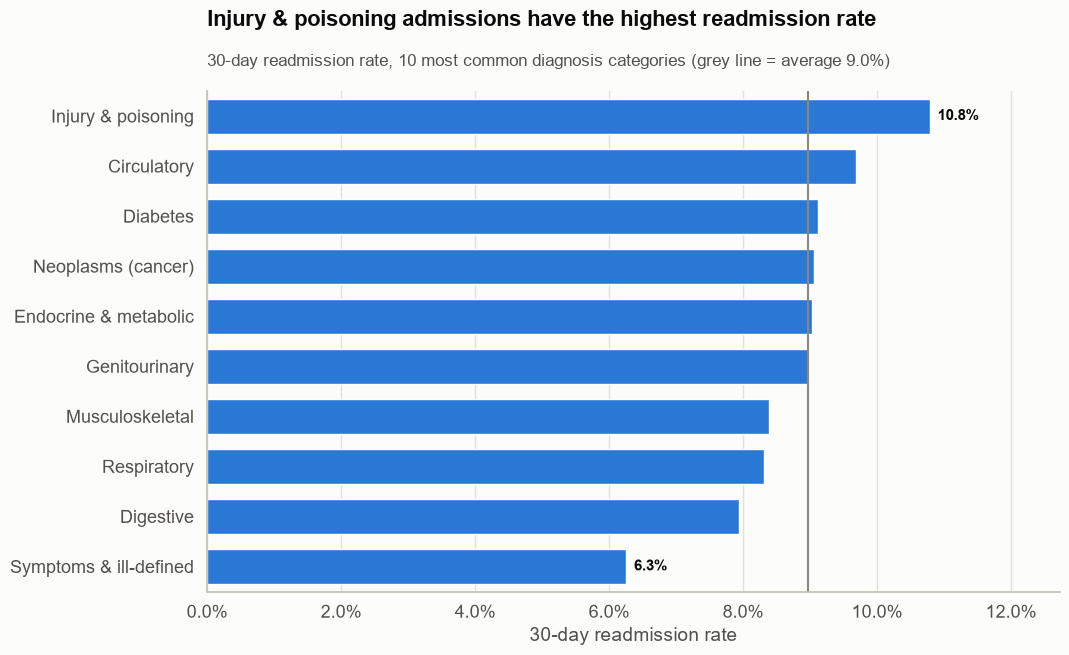

In [8]:
top10 = counts["diagnosis_category"]
table = rate_table(df[df["diagnosis_category"].isin(top10)], "diagnosis_category")
table = table.sort_values("readmission_rate", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(data=table, y="diagnosis_category", x="readmission_rate", color=BLUE, saturation=1, width=0.7, ax=ax)
ax.axvline(overall_rate, color=MUTED, linewidth=1.5)
label_bars(ax, [0, len(table) - 1], fmt="{:.1%}", horizontal=True)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, table["readmission_rate"].max() * 1.18)
ax.set_xlabel("30-day readmission rate")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
add_titles(ax, f"{table['diagnosis_category'].iloc[0]} admissions have the highest readmission rate",
           f"30-day readmission rate, 10 most common diagnosis categories (grey line = average {overall_rate:.1%})")
save_chart(fig, "readmission_by_diagnosis_category.png")

## 6. Who the patients are: age

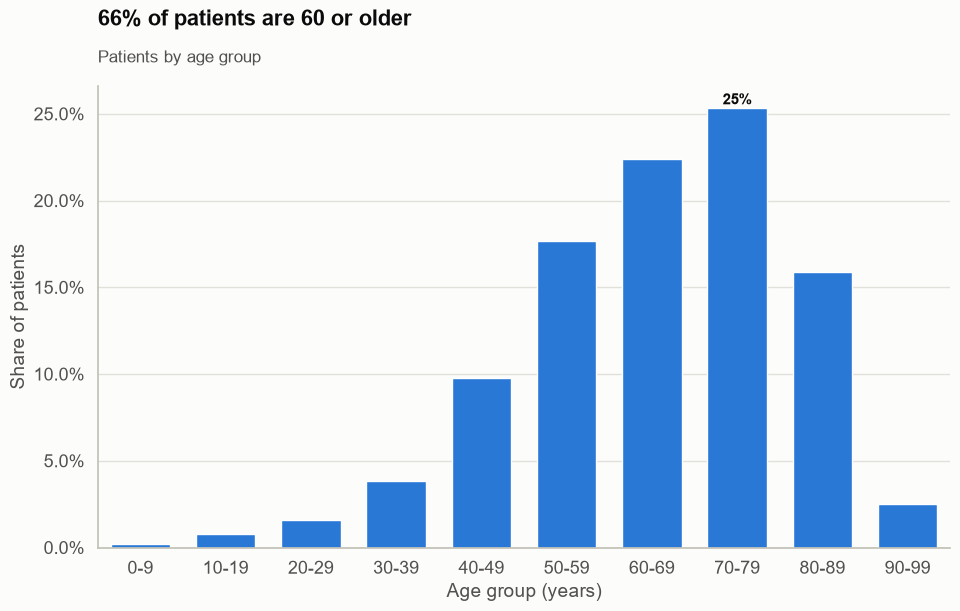

In [9]:
age_share = df["age_group"].value_counts(normalize=True).reindex(AGE_ORDER).reset_index()
age_share.columns = ["age_group", "share"]
share_60_plus = age_share.loc[age_share["age_group"] >= "60-69", "share"].sum()

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=age_share, x="age_group", y="share", color=BLUE, saturation=1, width=0.7, ax=ax)
label_bars(ax, [age_share["share"].idxmax()])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Share of patients")
add_titles(ax, f"{share_60_plus:.0%} of patients are 60 or older",
           "Patients by age group")
save_chart(fig, "patients_by_age_group.png")

## 7. Length of stay

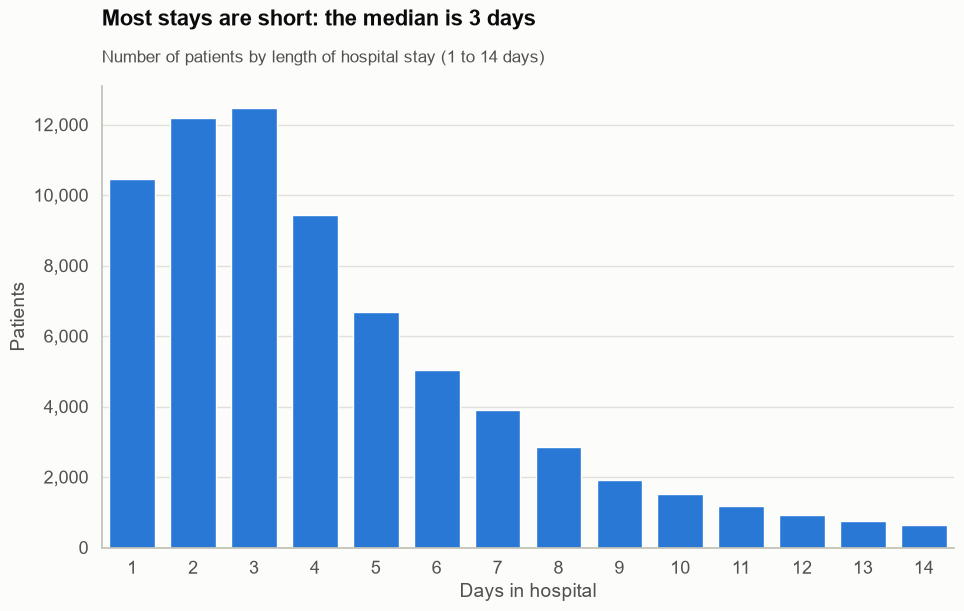

In [10]:
median_stay = df["length_of_stay"].median()

fig, ax = plt.subplots(figsize=(11, 6))
sns.countplot(data=df, x="length_of_stay", color=BLUE, saturation=1, width=0.75, ax=ax)
ax.set_xlabel("Days in hospital")
ax.set_ylabel("Patients")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")   # 10,000 instead of 10000
add_titles(ax, f"Most stays are short: the median is {median_stay:.0f} days",
           "Number of patients by length of hospital stay (1 to 14 days)")
save_chart(fig, "length_of_stay_distribution.png")

## 8. Length of stay by age group

In a box plot, the **line inside the box is the median**, the box covers the **middle half** of patients, and the whiskers show the usual range. Extreme values (outliers) are hidden to keep the chart clean.

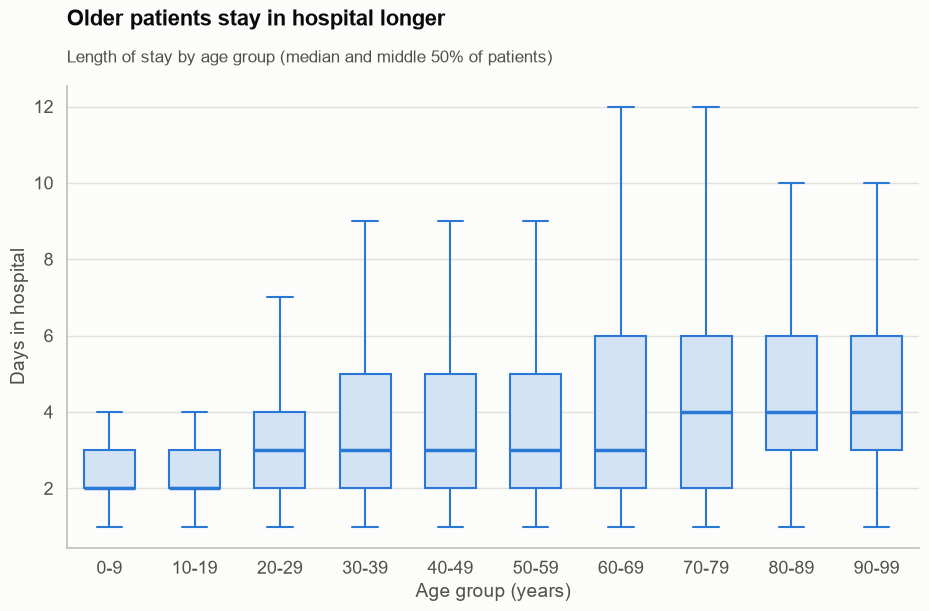

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=df, x="age_group", y="length_of_stay", order=AGE_ORDER,
    color=LIGHT_BLUE, width=0.6, showfliers=False, linecolor=BLUE, linewidth=1.5,
    medianprops={"color": BLUE, "linewidth": 2.5}, ax=ax,
)
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Days in hospital")
add_titles(ax, "Older patients stay in hospital longer",
           "Length of stay by age group (median and middle 50% of patients)")
save_chart(fig, "length_of_stay_by_age.png")

## 9. Readmission by insulin dose

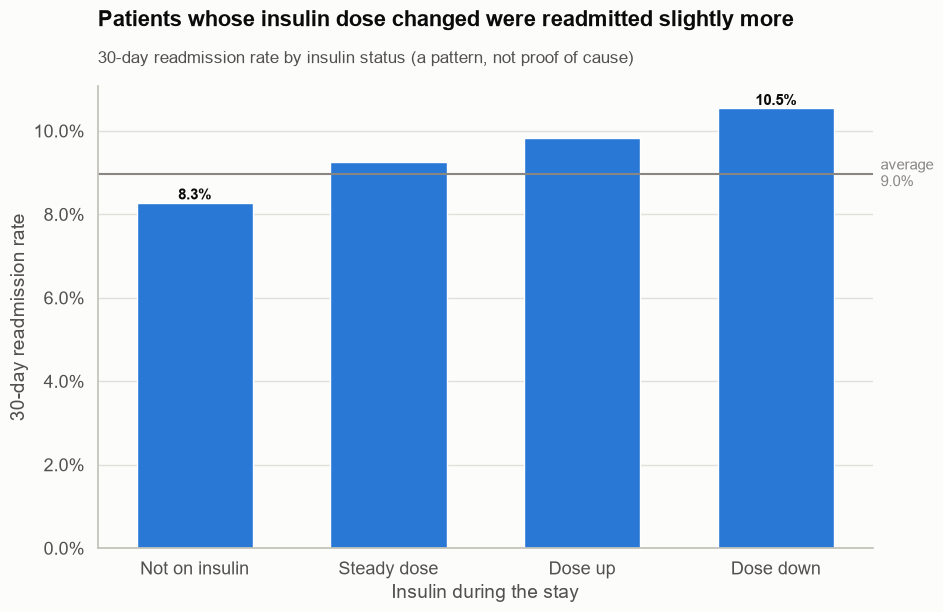

In [12]:
table = rate_table(df, "insulin_status", list(INSULIN_NAMES.values()))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=table, x="insulin_status", y="readmission_rate", color=BLUE, saturation=1, width=0.6, ax=ax)
add_average_line(ax, overall_rate, average_label)
label_bars(ax, [0, len(table) - 1], fmt="{:.1%}")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Insulin during the stay")
ax.set_ylabel("30-day readmission rate")
add_titles(ax, "Patients whose insulin dose changed were readmitted slightly more",
           "30-day readmission rate by insulin status (a pattern, not proof of cause)")
save_chart(fig, "readmission_by_insulin.png")

## 10. Correlation heatmap

Blue = the two numbers rise together, red = one rises as the other falls, grey = no relationship. Only the lower half is shown, because the upper half is a mirror image.

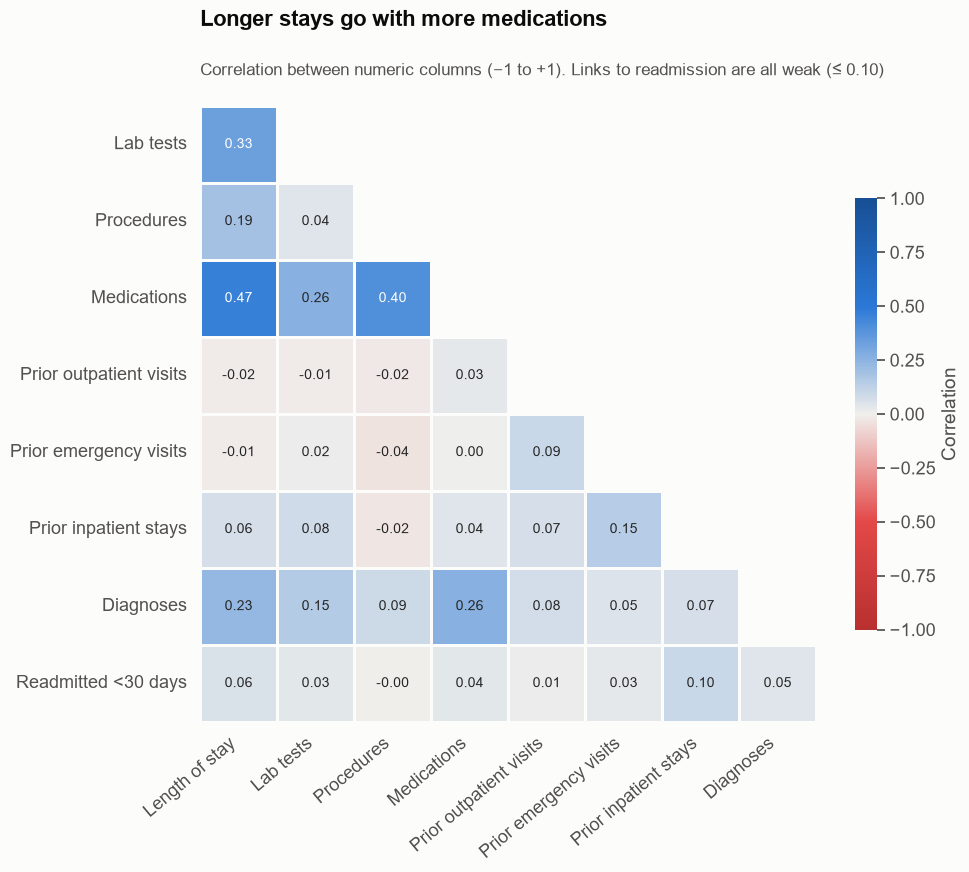

In [13]:
import numpy as np

columns = {
    "length_of_stay": "Length of stay",
    "num_lab_procedures": "Lab tests",
    "num_procedures": "Procedures",
    "num_medications": "Medications",
    "number_outpatient": "Prior outpatient visits",
    "number_emergency": "Prior emergency visits",
    "number_inpatient": "Prior inpatient stays",
    "number_diagnoses": "Diagnoses",
    "readmit_flag": "Readmitted <30 days",
}
corr = df[list(columns)].rename(columns=columns).corr()

# Keep only the lower triangle: the upper half repeats it, and the diagonal is always 1.
# Dropping the first row and last column removes the row/column that would be empty.
corr = corr.iloc[1:, :-1]
hide = np.triu(np.ones_like(corr, dtype=bool), k=1)   # k=1: keep the new diagonal

red_grey_blue = LinearSegmentedColormap.from_list(
    "red_grey_blue", ["#b8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=hide, cmap=red_grey_blue, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 10}, linewidths=2, linecolor=BACKGROUND, square=True,
            cbar_kws={"shrink": 0.7, "label": "Correlation"}, ax=ax)
ax.grid(False)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
add_titles(ax, "Longer stays go with more medications",
           "Correlation between numeric columns (−1 to +1). Links to readmission are all weak (≤ 0.10)")
save_chart(fig, "correlation_heatmap.png")

## Saved files

In [14]:
for path in saved_files:
    size_kb = path.stat().st_size / 1024
    print(f"{path.relative_to(PROJECT_DIR)}   ({size_kb:.0f} KB)")
print(f"\n{len(saved_files)} charts saved")

reports\figures\readmission_by_prior_inpatient_visits.png   (66 KB)
reports\figures\readmission_by_age.png   (68 KB)
reports\figures\readmission_by_medication_count.png   (63 KB)
reports\figures\top_diagnosis_categories.png   (85 KB)
reports\figures\readmission_by_diagnosis_category.png   (87 KB)
reports\figures\patients_by_age_group.png   (57 KB)
reports\figures\length_of_stay_distribution.png   (45 KB)
reports\figures\length_of_stay_by_age.png   (52 KB)
reports\figures\readmission_by_insulin.png   (66 KB)
reports\figures\correlation_heatmap.png   (147 KB)

10 charts saved
